# Hands-on 37: Studi Kasus C - Smart Energy Analytics

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 14.

Data konsumsi energi dengan pola harian kerja/akhir pekan + 20 anomali lonjakan.
Random Forest memprediksi beban langkah berikutnya; alert bila daya > 500 W atau
|forecast error| > 80 W.

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Generate Data Energi

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/case_c_generate_energy.py"], capture_output=True, text=True)
print(r.stdout)

## 2. Forecasting + Alert

In [3]:
r = subprocess.run([sys.executable, "scripts/case_c_energy_forecast_alert.py"], capture_output=True, text=True)
print(r.stdout[:1500])

MAE : 16.303139156359695
RMSE: 28.527013690217423
               timestamp  power_watt  ...  forecast_error_abs  alert_abnormal_load
3019 2026-01-22 00:10:00  117.680000  ...           17.413051                    0
3020 2026-01-22 00:20:00  110.740000  ...           16.725540                    0
3021 2026-01-22 00:30:00   94.820000  ...           21.799693                    0
3022 2026-01-22 00:40:00   88.330000  ...           14.345574                    0
3023 2026-01-22 00:50:00  124.700000  ...            6.994967                    0
3024 2026-01-22 01:00:00  117.110000  ...          213.604345                    1
3025 2026-01-22 01:10:00  323.755675  ...           18.175535                    0
3026 2026-01-22 01:20:00  112.160000  ...           14.247799                    0
3027 2026-01-22 01:30:00  112.260000  ...           15.646021                    0
3028 2026-01-22 01:40:00  105.300000  ...           17.031335                    0
3029 2026-01-22 01:50:00   90.770000 

## 3. Visualisasi Aktual vs Prediksi + Alert

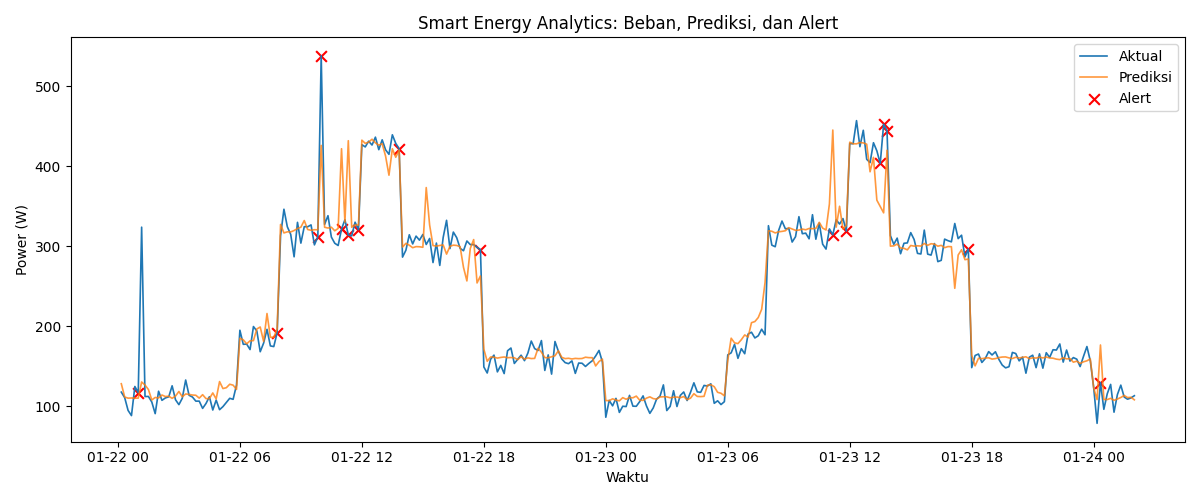

In [4]:
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

df = pd.read_csv("outputs/reports/case_c_energy_results.csv")
df["timestamp"] = pd.to_datetime(df["timestamp"])
sample = df.iloc[:300]

plt.figure(figsize=(12, 5))
plt.plot(sample["timestamp"], sample["power_watt"], label="Aktual", linewidth=1.2)
plt.plot(sample["timestamp"], sample["pred_next"], label="Prediksi", linewidth=1.2, alpha=0.8)
alerts = sample[sample["alert_abnormal_load"] == 1]
plt.scatter(alerts["timestamp"], alerts["power_watt"], color="red", marker="x", s=60, label="Alert")
plt.title("Smart Energy Analytics: Beban, Prediksi, dan Alert")
plt.xlabel("Waktu")
plt.ylabel("Power (W)")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/figures/case_c_energy_alert.png")
plt.close()
from IPython.display import Image
Image("outputs/figures/case_c_energy_alert.png")

## Penutup

Model memprediksi beban 10 menit ke depan dengan MAE sekitar 16 W. Alert beban tidak
normal terpicu pada lonjakan anomali (error forecast besar) dan beban di atas 500 W:
44 alert dari 1294 baris test. Cocok untuk lab komputer, ruang server, gedung kecil,
dan UMKM. Hasil di `outputs/reports/case_c_energy_results.csv`.

## Catatan dari buku: pengamatan, variasi, dan latihan

Bagian berikut disalin dari buku (Hands-on 39 dalam urutan buku) sebagai panduan pengamatan dan latihan mandiri setelah menjalankan notebook ini.

### 6. Evaluasi

Forecasting:
- MAE
- RMSE
- plot aktual vs prediksi
Alert:
- precision / recall bila ada anomali sintetis
- atau verifikasi visual operasional

### 6. Fallback

- jika buffer belum penuh, pakai nilai saat ini atau strategi lain yang
konsisten

Kenapa preprocessing otomatis penting?
Karena tanpa itu:
- model menerima data mentah yang belum siap,
- inferensi jadi rapuh,
- dan sistem akan sering gagal saat data lapangan “tidak cantik”.
Referensi juga menekankan bahwa heterogenitas data IoT menuntut
cleansing, ordering, and preprocessing agar prediksi tidak menjadi salah.

15.9 Model anomaly detection

Untuk proyek akhir ini, model yang paling realistis adalah Isolation Forest sebagai model
utama, dengan threshold sederhana sebagai baseline operasional.
Mengapa threshold tetap dipakai?
Karena:
- transparan,
- mudah dipahami,
- dan bagus untuk alarm cepat.
Mengapa Isolation Forest?
Karena:

tidak membutuhkan label lengkap,
cocok untuk data tabular hasil preprocessing,
ringan,
dan sangat praktis untuk sistem IoT yang fokus pada deteksi penyimpangan.

Strategi hybrid yang disarankan
Pendekatan terbaik untuk proyek akhir:
- threshold untuk alarm yang sangat jelas
- Isolation Forest untuk pola yang lebih halus
- keduanya ditampilkan pada dashboard
Ini sejalan dengan pendekatan buku sebelumnya bahwa threshold vs model ML
tidak harus dipertentangkan, tetapi bisa dipakai bersama.

15.10 Dashboard Grafana
Dashboard proyek akhir minimal sebaiknya memuat:

sensor utama real-time
histori sensor utama
skor atau status anomali
jumlah alert
panel status perangkat
daftar alert terbaru

Panel yang disarankan
Panel 1 — data sensor utama
- suhu / arus / daya / getaran
Panel 2 — skor anomali

- field numerik hasil model atau label
Panel 3 — status perangkat
- normal
- warning
- anomaly
Panel 4 — alert terbaru
- tabel alert paling baru
Panel 5 — histori distribusi
- untuk melihat drift atau perubahan pola
Grafana sangat cocok untuk ini karena sejak awal buku memang diarahkan menjadi
dashboard utama untuk time series open source.

15.11 Notifikasi sederhana
Untuk tahap buku, notifikasi cukup dibuat sederhana dan jelas.

Opsi notifikasi yang realistis

publish ke topik MQTT alert
log ke measurement khusus
panel merah di Grafana
terminal message
file log CSV

Contoh aturan notifikasi

skor anomali > ambang
suhu dan CO₂ sama-sama tinggi
arus melonjak di luar baseline
sensor berhenti kirim data terlalu lama
Prinsip utamanya:
notifikasi harus cukup berguna, bukan terlalu berisik.

15.12 Cara pengujian
15.12.1 Uji aliran dasar
Pastikan:

publisher bisa kirim ke broker
subscriber bisa menerima
payload bisa diparse
data masuk ke storage

15.12.2 Uji preprocessing
Coba:

payload normal
payload field hilang
payload tipe salah
payload nilai ekstrim

15.12.3 Uji model
Periksa:
- model bisa dimuat
- inferensi keluar konsisten
- skor anomali masuk akal

15.12.4 Uji dashboard
Periksa:
- data sensor muncul
- histori bergerak
- alert muncul saat dipicu

15.12.5 Uji skenario anomali
Gunakan synthetic generator untuk:

spike mendadak
drift perlahan
nilai sensor palsu
burst pesan cepat

15.12.6 Uji stabilitas ringan
Biarkan sistem berjalan beberapa waktu, lalu cek:

error log
jumlah pesan diterima
jumlah pesan gagal
apakah dashboard tetap hidup

15.13 Cara pengembangan lanjut
Berikut arah pengembangan yang sangat masuk akal setelah proyek akhir ini berhasil:

15.13.1 Multi-device
Dari satu perangkat menjadi:
- room01, room02, lab01
- atau banyak node sensor

15.13.2 Multi-sensor fusion
Gabungkan lebih banyak sensor:

suhu
kelembaban
CO₂
arus
daya
getaran

15.13.3 Retraining berkala
Tambahkan script:
- retraining mingguan
- evaluasi drift
- versioning model

15.13.4 Edge deployment
Pindahkan subscriber + inferensi ke:
- Raspberry Pi
- mini PC
- gateway lokal

15.13.5 Alert yang lebih matang
Tambahkan:
- threshold dinamis
- integrasi Telegram / email / WhatsApp

- severity level

15.13.6 Keamanan lebih baik
Tambahkan:

autentikasi MQTT lebih ketat
TLS
segmentasi topik dan hak akses
manajemen secret yang lebih rapi

15.13.7 Docker untuk reproducibility
Setelah sistem dipahami, bungkus dengan Docker agar:
- setup mudah diulang
- mudah dipindah mesin
- mudah diajarkan ke kelas lain
Docker sebagai opsi, bukan syarat wajib.

15.14 Alur implementasi proyek akhir yang disarankan
Agar pembaca tidak tersesat, berikut alur paling sehat:

Tahap 1 — mulai dari simulator
Gunakan publisher sintetis agar pipeline cepat hidup.

Tahap 2 — hidupkan MQTT dan subscriber
Pastikan aliran data berjalan stabil.

Tahap 3 — tambahkan preprocessing otomatis
Jangan langsung memanggil model sebelum validasi dan fitur dasar siap.

Tahap 4 — tambahkan model anomaly detection
Mulai dari threshold, lalu tambah Isolation Forest.

Tahap 5 — simpan hasil ke storage
Gunakan InfluxDB atau SQLite.

Tahap 6 — buat dashboard Grafana
Tampilkan sensor, skor, dan alert.

Tahap 7 — tambahkan notifikasi sederhana
Gunakan topik MQTT alert atau panel khusus.

Tahap 8 — uji kondisi buruk
Coba synthetic drift, spike, dan payload rusak.

Tahap 9 — rapikan struktur proyek
Simpan model, log, dashboard, dan skrip dengan rapi.

15.15 Contoh keluaran proyek akhir yang baik
Sebuah proyek akhir yang berhasil seharusnya menghasilkan:

publisher/simulator berjalan stabil
subscriber menerima dan memproses data otomatis
model anomaly detection aktif
histori data tersimpan
dashboard real-time hidup
alert muncul saat kondisi abnormal
proyek bisa diulang di mesin lain dengan setup yang jelas

15.16 Sikap profesional dalam proyek akhir
Ada satu pelajaran penting yang ingin ditekankan di bab penutup ini:
proyek akhir yang baik bukan proyek yang paling banyak
komponennya, tetapi proyek yang paling utuh, stabil, dan bisa
dijelaskan.
Artinya:
- lebih baik satu pipeline kecil tetapi lengkap,
- daripada banyak ide besar tetapi tidak benar-benar terhubung.
Di dunia nyata, sistem yang berguna adalah sistem yang:

datanya valid,
modelnya masuk akal,
dashboard-nya terbaca,
alert-nya berguna,
dan mudah dirawat.

15.17 Penutup bab